# Рисунок 3. Наклоны спектров
Расчёт метрик по CWT-мощности и построение сравнительного рисунка.

In [ ]:
from pathlib2 import Path
import numpy as np
from spectral_slope_calc import compute_all, plot_slopes

### Инициализация путей

In [2]:
work_dir = Path(r"C:\Users\alvar\Documents\practice\test_repo_spectral_analysis")
path_to_data = work_dir / "sum_edges_triples"

path_to_sum_edges_native = path_to_data / "head_data"
path_to_sum_edges_synthetic = path_to_data / "sum_edges_triples_synthetic_data.npz"

path_to_cwt = work_dir / "cwt_results"
path_to_cwt_native = path_to_cwt / "native"
path_to_cwt_native.mkdir(exist_ok=True, parents=True)

path_to_cwt_synthetic = path_to_cwt / "synthetic"
path_to_cwt_synthetic.mkdir(exist_ok=True, parents=True)

synthetic_cwt = {
    "edges": path_to_cwt_synthetic / "cwt_res_edges_synthetic.npz",
    "triples": path_to_cwt_synthetic / "cwt_res_triples_synthetic.npz"
}

path_to_save_slopes = work_dir / "slopes" / "slopes_cache.json"

path_to_save_figure = work_dir / "figures" / "spectral_slopes"
path_to_save_figure.mkdir(exist_ok=True, parents=True)

output_pdf = path_to_save_figure / "spectral_slopes.pdf"
output_png = path_to_save_figure / "spectral_slopes.png"

### Определение параметров

In [3]:
# compute_all сначала использует slopes_cache.json.
# Если кэша нет, загружает CWT-файлы; при их отсутствии рассчитывает CWT
# по исходным sum_edges / sum_triples.
recompute = True  # True — игнорировать кэш и пересчитать всё

In [4]:
mice = ["22", "23", "24", "25"]
days = ["1D", "2D", "3D"]
kinds = ["edges", "triples"]

fs = 20.0
wavelet_w = 6.0
frequencies = np.linspace(0.1, 10.0, 500)
f_range = (0.1, 10.0)
band = (2, 10.0)
n_log = 200
window_decades = 0.3

group_gap = 1.0
figsize_cm = (16, 8)
dpi = 300
show_figure = True

### Расчет метрик и отрисовка результатов

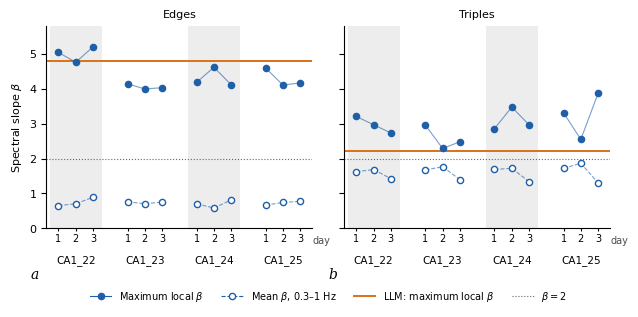

Сохранено: C:\Users\alvar\Documents\practice\test_repo_spectral_analysis\figures\spectral_slopes\spectral_slopes.pdf и C:\Users\alvar\Documents\practice\test_repo_spectral_analysis\figures\spectral_slopes\spectral_slopes.png


In [5]:
results = compute_all(
    mice=mice, days=days, kinds=kinds,
    cwt_dir=path_to_cwt_native, cwt_pattern="cwt_res_{kind}_{video}.npz",
    sum_dir=path_to_sum_edges_native, sum_pattern="{video}.npz",
    llm_cwt=synthetic_cwt, llm_sum=path_to_sum_edges_synthetic,
    frequencies_default=frequencies,
    cache_file=path_to_save_slopes,
    f_range=f_range, band=band, n_log=n_log,
    window_decades=window_decades,
    fs=fs, w=wavelet_w, recompute=recompute,
)

plot_slopes(
    results, mice, days, kinds,
    output_pdf=output_pdf, output_png=output_png,
    figsize_cm=figsize_cm, group_gap=group_gap,
    dpi=dpi, show=show_figure,
)